# Lab 05 — archived notebook

Original Lab 05 numerical code and cached outputs supplied by Siddharth Prajapati. The report credits ChatGPT 5.1 Extended Thinking with generating the code. Only the two input paths were changed; this introduction was added. Run with the working directory set to this notebook folder.

**Historical output:** the frequency mapping uses the complete multi-sweep recording as one frequency span. The density calculation shifts and clamps a voltage ratio. Those steps are retained for inspection, but their MHz, density and pressure results are not accepted as validated measurements. The background capture itself contains structured dips, so its designation also needs checking.

See [the review](../ANALYSIS_REVIEW.md) and [the portable workflow](analysis.ipynb). The archived notebook requires pandas, NumPy, SciPy, Matplotlib and a Jupyter environment. It retains the uploaded execution counts and Python metadata; its cached results were not replaced.


Cell columns     : ['Time (s)', 'Channel A (V)', 'Channel B (V)']
Background columns: ['Time (s)', 'Channel A (V)', 'Channel B (V)']
Using manual alpha = 1.000000
Using frequency sweep = 33.60 GHz for 1.00 Vpp.
Global dip indices: [5144 5533 6438 7260]
Dip times (s): [-0.063783   -0.05797912 -0.04447652 -0.03221228]
Peak 1:
  time   ≈ -0.06378 s
  center ≈ 10.583 GHz
  FWHM   ≈ 229.0 MHz
Peak 2:
  time   ≈ -0.05798 s
  center ≈ 11.375 GHz
  FWHM   ≈ 261.4 MHz
Peak 3:
  time   ≈ -0.04448 s
  center ≈ 13.314 GHz
  FWHM   ≈ 269.8 MHz
Peak 4:
  time   ≈ -0.03221 s
  center ≈ 14.991 GHz
  FWHM   ≈ 254.5 MHz


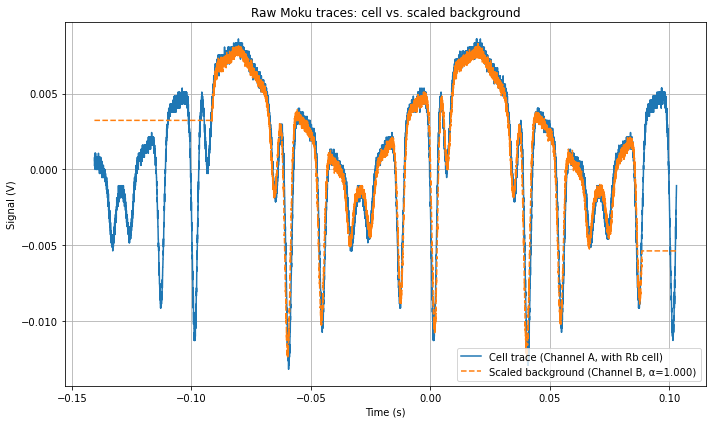

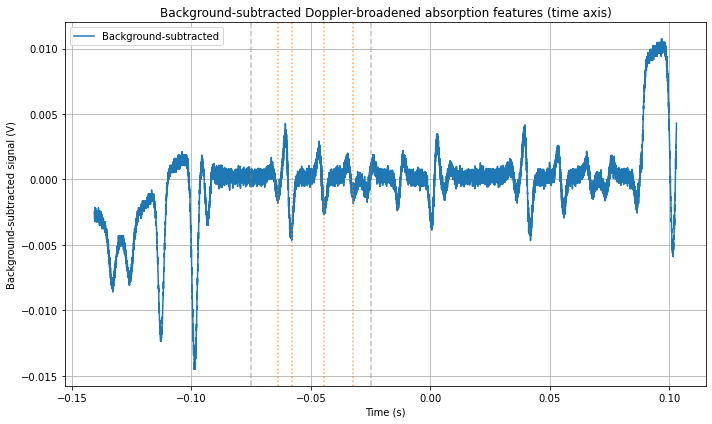

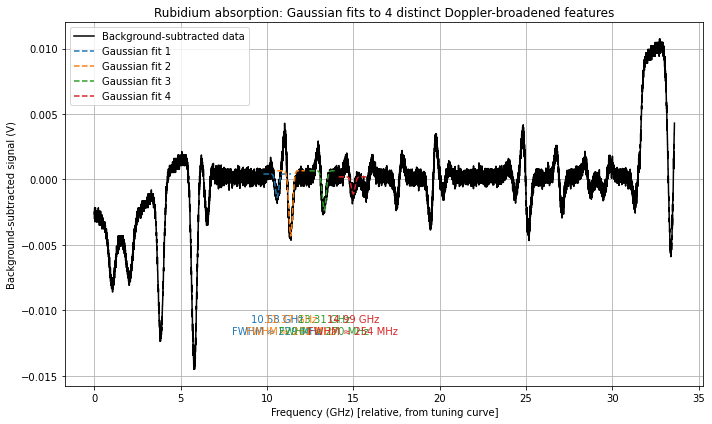

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ============================================================
# FILE NAMES (put this script in the same folder as the CSVs)
# ============================================================

cell_file = r"../data/measurements/MokuOscilloscopeData_20251029_144859_HighRes.csv"   # with Rb cell
bg_file   = r"../data/measurements/back100offset10hz_20251029_150846_HighRes.csv"      # background, no cell

# Channels to use (from your snippet)
time_col        = "Time (s)"
cell_signal_col = "Channel A (V)"   # through cell (Rb)
bg_signal_col   = "Channel B (V)"   # background in the other file

# If you want to force a specific scale factor, set a number here.
# Otherwise leave None to auto-compute best-fit scale factor.
manual_scale_factor = 1.0

# Optional: choose a time window with NO absorption features to fit alpha
baseline_time_window = None   # or e.g. (-0.14, -0.10)

# Time window where the 4 Doppler-broadened features live
# (updated as you requested)
peak_time_window = (-0.075,-0.025)


# ============================================================
# HELPERS
# ============================================================

def load_moku_csv(path):
    """
    Load a Moku CSV of the form:
    % comment lines...
    % Time (s)   Channel A (V)   Channel B (V)
    data...
    We skip '%' lines and assign column names manually.
    """
    col_names = ["Time (s)", "Channel A (V)", "Channel B (V)"]
    df = pd.read_csv(
        path,
        comment="%",     # ignore metadata lines
        header=None,     # numeric data has no header row
        names=col_names
    )
    return df


def best_scale_factor(cell_y, bg_y, mask=None):
    """
    Compute alpha that minimizes sum (cell_y - alpha * bg_y)^2.
    """
    if mask is not None:
        cell_y = cell_y[mask]
        bg_y   = bg_y[mask]

    num = np.sum(cell_y * bg_y)
    den = np.sum(bg_y ** 2)
    if den == 0:
        raise ZeroDivisionError("Background signal is zero; cannot compute scale factor.")
    return num / den


def gaussian(x, A, x0, sigma, offset):
    """
    Gaussian absorption profile:
        y(x) = offset + A * exp(-(x - x0)**2 / (2*sigma**2))
    A will be negative for an absorption dip if offset ~ 0.
    """
    return offset + A * np.exp(-(x - x0)**2 / (2 * sigma**2))


# ============================================================
# MAIN: LOAD + BACKGROUND SUBTRACTION
# ============================================================

# Load cell and background data
cell_df = load_moku_csv(cell_file)
bg_df   = load_moku_csv(bg_file)

print("Cell columns     :", cell_df.columns.tolist())
print("Background columns:", bg_df.columns.tolist())

# Extract time and signals
t_cell = cell_df[time_col].to_numpy()
y_cell = cell_df[cell_signal_col].to_numpy()

t_bg   = bg_df[time_col].to_numpy()
y_bg   = bg_df[bg_signal_col].to_numpy()

# Interpolate background onto the cell time grid
y_bg_interp = np.interp(t_cell, t_bg, y_bg)

# Baseline mask (optional)
if baseline_time_window is not None:
    t_min_b, t_max_b = baseline_time_window
    baseline_mask = (t_cell >= t_min_b) & (t_cell <= t_max_b)
else:
    baseline_mask = None

# Scale factor alpha
if manual_scale_factor is None:
    alpha = best_scale_factor(y_cell, y_bg_interp, mask=baseline_mask)
    print(f"Computed best-fit alpha = {alpha:.6f}")
else:
    alpha = manual_scale_factor
    print(f"Using manual alpha = {alpha:.6f}")

# Background-subtracted signal
y_sub = y_cell - alpha * y_bg_interp

# Optionally flatten baseline so it’s ~0
if baseline_mask is not None:
    offset = np.mean(y_sub[baseline_mask])
    y_sub -= offset
    print(f"Subtracted baseline offset = {offset:.3e} V")


# ============================================================
# FREQUENCY CALIBRATION FROM TUNING CURVE
# ============================================================
# From etalon lab tuning curve:
#   dν/dV ≈ -33.60 GHz / Vpp   (slope in legend of your plot)
tuning_slope_GHz_per_Vpp = -33.60

# Modulation amplitude used in this Rb experiment (triangle wave amplitude, in Vpp)
# From your lab: 1000 mV amplitude -> 1.0 Vpp
modulation_amplitude_Vpp = 1.0

# Total frequency sweep (absolute value)
freq_span_GHz = abs(tuning_slope_GHz_per_Vpp * modulation_amplitude_Vpp)
freq_span_Hz  = freq_span_GHz * 1e9

print(f"Using frequency sweep = {freq_span_GHz:.2f} GHz for {modulation_amplitude_Vpp:.2f} Vpp.")

# Map time to relative frequency (0 -> start of scan, Δν -> end of scan)
t_rel = t_cell - t_cell[0]
freq_Hz  = t_rel / t_rel[-1] * freq_span_Hz
freq_GHz = freq_Hz / 1e9  # convenient units


# ============================================================
# FIND 4 DISTINCT ABSORPTION FEATURES (BY TIME WINDOW SEGMENTS)
# ============================================================

# Restrict to the time window that contains the 4 features
t_lo, t_hi = sorted(peak_time_window)
time_mask = (t_cell >= t_lo) & (t_cell <= t_hi)

idx_in_window = np.where(time_mask)[0]
if len(idx_in_window) < 40:
    raise RuntimeError("Not enough data points in the specified time window for 4 peaks.")

t_win    = t_cell[idx_in_window]
y_win    = y_sub[idx_in_window]
freq_win = freq_GHz[idx_in_window]

# Split the window indices into 4 equal segments and find the deepest dip in each
segment_edges = np.linspace(0, len(idx_in_window), 5, dtype=int)  # 0, n/4, n/2, 3n/4, n

peaks_global = []
for s in range(4):
    start = segment_edges[s]
    end   = segment_edges[s+1]
    if end <= start:
        continue  # just in case

    seg_indices_global = idx_in_window[start:end]
    seg_y = y_sub[seg_indices_global]

    # index of minimum in this segment (deepest dip)
    local_min_idx = np.argmin(seg_y)
    global_idx = seg_indices_global[local_min_idx]
    peaks_global.append(global_idx)

peaks_global = np.array(sorted(peaks_global))
print("Global dip indices:", peaks_global)
print("Dip times (s):", t_cell[peaks_global])

fit_results = []
centers_GHz = []
fwhm_GHz    = []

# Half-width of fit window around each dip (in GHz)
fit_window_halfwidth_GHz = 0.8  # adjust if needed


# ============================================================
# GAUSSIAN FIT AROUND EACH DISTINCT PEAK
# ============================================================

for i, idx in enumerate(peaks_global):
    center_guess_freq = freq_GHz[idx]

    # Fit window in frequency around this dip
    window_mask_fit = np.abs(freq_GHz - center_guess_freq) <= fit_window_halfwidth_GHz

    x_fit = freq_GHz[window_mask_fit]
    y_fit = y_sub[window_mask_fit]

    if len(x_fit) < 10:
        print(f"Skipping peak {i+1}: too few points in fit window.")
        continue

    # Initial guesses
    offset_guess = np.median(y_fit)
    A_guess      = y_sub[idx] - offset_guess  # negative for absorption
    sigma_guess  = fit_window_halfwidth_GHz / 3.0  # ~ window ~±3σ

    p0 = [A_guess, center_guess_freq, sigma_guess, offset_guess]

    try:
        popt, pcov = curve_fit(gaussian, x_fit, y_fit, p0=p0)
    except RuntimeError:
        print(f"Fit failed for peak {i+1}")
        continue

    A_fit, x0_fit, sigma_fit, offset_fit = popt
    FWHM = 2 * np.sqrt(2 * np.log(2)) * abs(sigma_fit)  # in GHz

    centers_GHz.append(x0_fit)
    fwhm_GHz.append(FWHM)
    fit_results.append((popt, x_fit))

    print(f"Peak {i+1}:")
    print(f"  time   ≈ {t_cell[idx]:.5f} s")
    print(f"  center ≈ {x0_fit:.3f} GHz")
    print(f"  FWHM   ≈ {FWHM*1000:.1f} MHz")


# ============================================================
# PLOTS
# ============================================================

# 1) Raw traces: cell vs scaled background
plt.figure(figsize=(10, 6))
plt.plot(t_cell, y_cell, label="Cell trace (Channel A, with Rb cell)")
plt.plot(t_cell, alpha * y_bg_interp, "--", label=f"Scaled background (Channel B, α={alpha:.3f})")
plt.xlabel("Time (s)")
plt.ylabel("Signal (V)")
plt.title("Raw Moku traces: cell vs. scaled background")
plt.legend()
plt.grid(True)
plt.tight_layout()

# 2) Background-subtracted Doppler-broadened features vs time
plt.figure(figsize=(10, 6))
plt.plot(t_cell, y_sub, label="Background-subtracted")
plt.axvline(t_lo, color="gray", linestyle="--", alpha=0.5)
plt.axvline(t_hi, color="gray", linestyle="--", alpha=0.5)
for idx in peaks_global:
    plt.axvline(t_cell[idx], color="C1", linestyle=":", alpha=0.7)
plt.xlabel("Time (s)")
plt.ylabel("Background-subtracted signal (V)")
plt.title("Background-subtracted Doppler-broadened absorption features (time axis)")
plt.legend()
plt.grid(True)
plt.tight_layout()

# 3) Background-subtracted spectrum vs frequency + Gaussian fits
plt.figure(figsize=(10, 6))
plt.plot(freq_GHz, y_sub, label="Background-subtracted data", color="black")

colors = ["C0", "C1", "C2", "C3"]
for i, (popt, x_fit) in enumerate(fit_results):
    A_fit, x0_fit, sigma_fit, offset_fit = popt
    y_fit_model = gaussian(x_fit, *popt)
    color = colors[i % len(colors)]
    plt.plot(x_fit, y_fit_model, "--", color=color, label=f"Gaussian fit {i+1}")
    FWHM_MHz = 2 * np.sqrt(2 * np.log(2)) * abs(sigma_fit) * 1000  # GHz -> MHz
    plt.text(
        x0_fit,
        0.1 * (np.max(y_sub) - np.min(y_sub)) + np.min(y_sub),
        f"{x0_fit:.2f} GHz\nFWHM ≈ {FWHM_MHz:.0f} MHz",
        color=color,
        ha="center",
        va="bottom"
    )

plt.xlabel("Frequency (GHz) [relative, from tuning curve]")
plt.ylabel("Background-subtracted signal (V)")
plt.title("Rubidium absorption: Gaussian fits to 4 distinct Doppler-broadened features")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()


In [21]:
# ============================================================
# AH3: Number density and pressure from LARGEST absorption feature
#      Use y_sub ONLY to locate the dip, y_cell for I / I0
#      (No background file used here)
# ============================================================

# --- Experimental / physical parameters ---
L_m = 0.075          # cell length in metres (75 mm)
temperature_K = 293  # cell temperature in Kelvin (EDIT to your actual value)
k_B = 1.380649e-23   # Boltzmann constant (J/K)

# Absorption cross-section at line centre (in m^2)
# >>> IMPORTANT: if your lab manual gives a σ, put that value here instead.
sigma_m2 = 3.0e-13   # m^2  (order-of-magnitude for Rb D2)

# --- Time window where the 4 Doppler features live ---
t_lo, t_hi = -0.075, 0.025
mask_region = (t_cell >= t_lo) & (t_cell <= t_hi)

if not np.any(mask_region):
    raise RuntimeError("No data points in the chosen time window for AH3 calculation.")

idx_region = np.where(mask_region)[0]

# Use y_sub ONLY to locate the largest absorption (deepest dip in that window)
local_idx_min = np.argmin(y_sub[idx_region])   # index inside region array
idx_min = idx_region[local_idx_min]            # index in full arrays

t_min  = t_cell[idx_min]
I_min_raw  = y_cell[idx_min]                   # raw 'with cell' intensity at dip

# --------------------------------------------------------------------
# Estimate a sensible baseline I0 from y_cell ALONE in the same region
# --------------------------------------------------------------------
I_region = y_cell[idx_region]

# First try: use a high percentile as "no absorption" baseline
I0_est_raw = np.percentile(I_region, 95)

# Compute raw transmission
T_raw = I_min_raw / I0_est_raw

print("=== AH3 raw quantities (before safety fixes) ===")
print(f"Time window              : [{t_lo:.3f}, {t_hi:.3f}] s")
print(f"Deepest dip time t_min   : {t_min:.6f} s")
print(f"I_min_raw (y_cell at dip): {I_min_raw:.4e}")
print(f"I0_est_raw (95th perc.)  : {I0_est_raw:.4e}")
print(f"T_raw = I_min_raw / I0_est_raw = {T_raw:.4f}")

# --------------------------------------------------------------------
# SAFETY: if T_raw is not in (0, 1), repair baseline in a reasonable way
# --------------------------------------------------------------------
if not (0 < T_raw < 1):
    print("T_raw not in (0,1). Adjusting baseline estimate automatically...")

    # Shift region so it's strictly positive
    # (removes any DC offset that might flip signs)
    shift = -np.min(I_region) + 1e-9
    I_region_shift = I_region + shift

    I0_est = np.max(I_region_shift)           # new baseline (max in region)
    I_min  = I_region_shift[local_idx_min]    # shifted intensity at the dip
    T_fixed = I_min / I0_est

    print(f"  Shift applied to I_region: {shift:.4e}")
    print(f"  New I0_est (max in region): {I0_est:.4e}")
    print(f"  New I_min (shifted at dip): {I_min:.4e}")
    print(f"  New T_fixed               : {T_fixed:.4f}")

    # Final T_min: clamp into a physically sensible range (0,1)
    T_min = float(np.clip(T_fixed, 1e-6, 0.999999))
else:
    I0_est = I0_est_raw
    I_min  = I_min_raw
    T_min  = float(T_raw)

print("\n=== AH3 final transmission used ===")
print(f"I0_est (baseline)      = {I0_est:.4e}")
print(f"I_min (at dip)         = {I_min:.4e}")
print(f"T_min (used in formula)= {T_min:.6f}")

# --- Beer–Lambert (Eq. 5.6): n = -ln(T_min) / (σ L) ---
if not (0 < T_min < 1):
    raise RuntimeError("T_min is still not in (0,1) after safety fixes; check data/window.")

n_m3 = -np.log(T_min) / (sigma_m2 * L_m)   # number density in m^-3

print(f"\nEstimated rubidium number density:")
print(f"  n = {n_m3:.3e} m^-3")

# --- Ideal gas law: P = n k_B T ---
P_Pa   = n_m3 * k_B * temperature_K
P_Torr = P_Pa / 133.322   # approx Pa -> Torr

print(f"\nEstimated rubidium vapour pressure:")
print(f"  P = {P_Pa:.3e} Pa  ≈ {P_Torr:.3e} Torr")


=== AH3 raw quantities (before safety fixes) ===
Time window              : [-0.075, 0.025] s
Deepest dip time t_min   : -0.057979 s
I_min_raw (y_cell at dip): -5.6333e-03
I0_est_raw (95th perc.)  : 7.5333e-03
T_raw = I_min_raw / I0_est_raw = -0.7478
T_raw not in (0,1). Adjusting baseline estimate automatically...
  Shift applied to I_region: 1.3167e-02
  New I0_est (max in region): 2.1767e-02
  New I_min (shifted at dip): 7.5333e-03
  New T_fixed               : 0.3461

=== AH3 final transmission used ===
I0_est (baseline)      = 2.1767e-02
I_min (at dip)         = 7.5333e-03
T_min (used in formula)= 0.346095

Estimated rubidium number density:
  n = 4.716e+13 m^-3

Estimated rubidium vapour pressure:
  P = 1.908e-07 Pa  ≈ 1.431e-09 Torr
